In [ ]:
# Permutation Feature Importance

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.inspection import permutation_importance
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)
df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_features:
    X_train[col] = X_train[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )
lr_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/logistic_r_model.pkl")
knn_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl")
dt_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/decision_tree_model.pkl")
rf_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl")
svm_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/svm_model.pkl")

models = {
    "Logistic Regression": lr_model,
    "KNN (K=16)": knn_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Tuned SVM": svm_model
}

In [7]:
# Calculate permutation importance
perm_importance = permutation_importance(
    svm_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_importance.importances_mean,
    "Importance Std": perm_importance.importances_std
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance Mean",
    ascending=False
)

print(feature_importance)

     Feature  Importance Mean  Importance Std
2         cp         0.060258        0.016084
1        sex         0.025676        0.005722
10     slope         0.018418        0.008188
9    oldpeak         0.016236        0.006273
12      thal         0.014568        0.007214
11        ca         0.009882        0.007059
4       chol         0.009116        0.006360
5        fbs         0.006576        0.002542
7     thalch         0.006570        0.004804
3   trestbps        -0.000185        0.000564
8      exang        -0.000329        0.000372
6    restecg        -0.001375        0.001501
0        age        -0.002194        0.004549


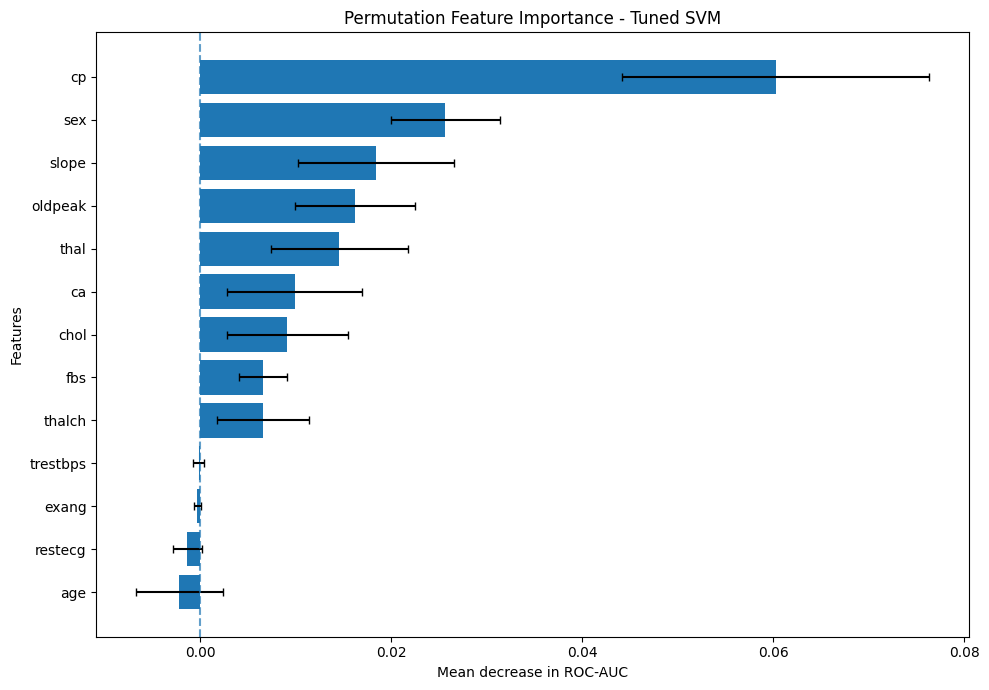

In [11]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance Mean"],
    xerr=feature_importance["Importance Std"],
    capsize=3
)

plt.axvline(x=0, linestyle="--", alpha=0.7)

plt.xlabel("Mean decrease in ROC-AUC")
plt.ylabel("Features")
plt.title("Permutation Feature Importance - Tuned SVM")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("D:/1_Python Programmes/Projects/HDD/reports/svm_feature_importance.png", dpi=300)
plt.show()

In [12]:
# Select numerical features from training data
numerical_data = X_train.select_dtypes(include=np.number)

# Calculate correlation matrix
correlation_matrix = numerical_data.corr(method="pearson")

print(correlation_matrix.round(2))

           age  trestbps  chol  thalch  oldpeak    ca
age       1.00      0.25  0.09   -0.38     0.26  0.37
trestbps  0.25      1.00  0.09   -0.09     0.19  0.05
chol      0.09      0.09  1.00   -0.03     0.02  0.11
thalch   -0.38     -0.09 -0.03    1.00    -0.16 -0.25
oldpeak   0.26      0.19  0.02   -0.16     1.00  0.30
ca        0.37      0.05  0.11   -0.25     0.30  1.00


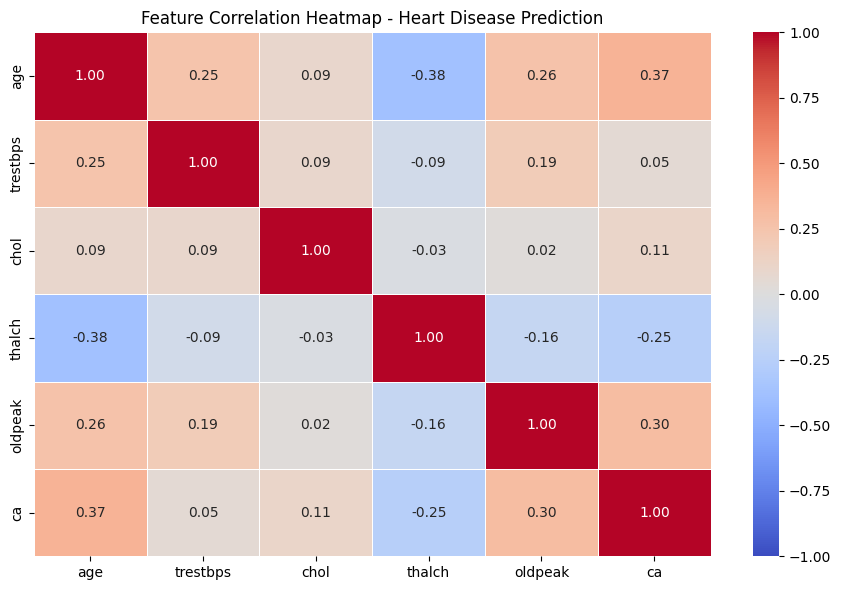

In [15]:
plt.figure(figsize=(9, 6))

# Absolute correlation	Interpretation
# 0.00–0.30	                Weak
# 0.30–0.70	              Moderate
# 0.70–1.00              	Strong

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Feature Correlation Heatmap - Heart Disease Prediction")
plt.tight_layout()

# plt.savefig(
#     "D:/1_Python Programmes/Projects/HDD/reports/correlation_heatmap.png",
#     dpi=300
# )

plt.show()

In [19]:
def cramers_v(x, y):

    confusion_matrix = pd.crosstab(x, y)

    chi2 = chi2_contingency(
        confusion_matrix,
        correction=False
    )[0]

    n = confusion_matrix.sum().sum()

    if n <= 1:
        return np.nan

    r, k = confusion_matrix.shape

    phi2 = chi2 / n

    # Bias correction
    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(
        k_corrected - 1,
        r_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corrected / denominator)


# Select categorical features
cat_data = X_train[categorical_features].copy()

# Standardize categorical values and handle missing values
for col in categorical_features:
    cat_data[col] = (
        cat_data[col]
        .astype("string")
        .fillna("__MISSING__")
    )

# Create empty association matrix
cramers_matrix = pd.DataFrame(
    np.zeros((len(categorical_features), len(categorical_features))),
    index=categorical_features,
    columns=categorical_features
)

# Calculate pairwise Cramér's V
for col1 in categorical_features:

    for col2 in categorical_features:

        cramers_matrix.loc[col1, col2] = cramers_v(
            cat_data[col1],
            cat_data[col2]
        )

print(cramers_matrix.round(3))

           sex     cp    fbs  restecg  exang  slope   thal
sex      1.000  0.185  0.129    0.057  0.199  0.059  0.298
cp       0.185  1.000  0.089    0.046  0.317  0.184  0.158
fbs      0.129  0.089  1.000    0.132  0.102  0.079  0.099
restecg  0.057  0.046  0.132    1.000  0.151  0.178  0.308
exang    0.199  0.317  0.102    0.151  1.000  0.373  0.230
slope    0.059  0.184  0.079    0.178  0.373  1.000  0.322
thal     0.298  0.158  0.099    0.308  0.230  0.322  1.000


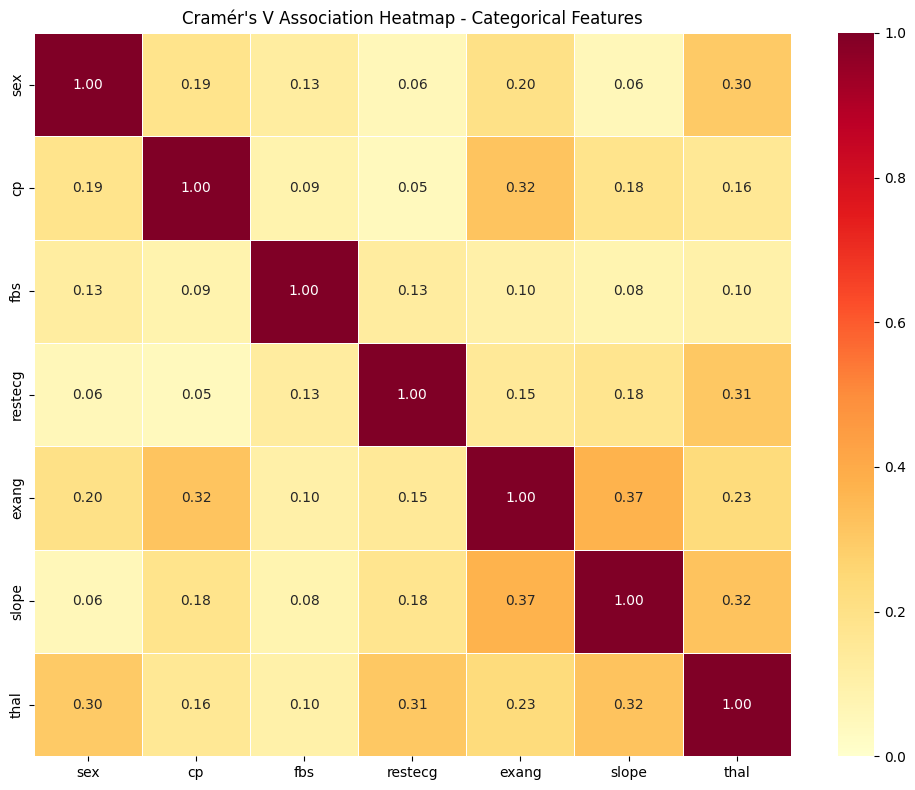

In [22]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cramers_matrix,
    annot=True,
    cmap="YlOrRd",
    fmt=".2f",
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Cramér's V Association Heatmap - Categorical Features")
plt.tight_layout()

plt.savefig(
    "D:/1_Python Programmes/Projects/HDD/reports/cramers_v_heatmap.png",
    dpi=300
)

plt.show()